# CIE 2 – Activity 1: Multiple Linear Regression Worksheet
**Course:** Regression and Classification Algorithms | **Class:** T.Y. B.Tech AI & DS, Div C, Sem V, 2026–27
**Name:** Ayush Rajgure | **Roll No.:** AD3304

> Role: data analyst at a health-research institute asked to explain and forecast diabetes disease progression from routine baseline measurements.

## 1. Problem framing (Thinking Cycle, stage 1)
- **Who uses the result?** A clinical research team that wants to know which baseline measurements are associated with faster disease progression one year later.
- **Decision supported:** which routine measurements deserve attention in follow-up studies. *This is an exploratory analysis, not a diagnostic tool.*
- **Target (y):** `target`, a quantitative measure of disease progression one year after baseline (continuous, no unit given by the source).
- **Inputs (X):** `age`, `bmi`, `bp`, `s1`–`s6` (nine numeric features, listed in the data dictionary below).
- **Success metric:** test-set RMSE (in target units) and test R², with adjusted R² to penalise useless features. A model must beat the "predict the mean" baseline.

## 2. Dataset and data dictionary (stage 2)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 4)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
# scaled=False gives the ORIGINAL measurement units (the default version is pre-standardised).
raw = load_diabetes(as_frame=True, scaled=False)
df = raw.frame.copy()
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


**Source:** Efron, Hastie, Johnstone & Tibshirani (2004), *Least Angle Regression*, Annals of Statistics 32(2). Data page: https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html. Loaded through `sklearn.datasets.load_diabetes` (open data, bundled with scikit-learn). File type: in-memory DataFrame (CSV-equivalent). 442 rows × 11 columns. **One row = one diabetes patient.**

| Column | Meaning | Why it may influence y |
|---|---|---|
| age | age in years | disease burden tends to change with age |
| bmi | body mass index | excess body weight is linked to insulin resistance |
| bp | average blood pressure | cardiovascular and metabolic conditions often co-occur |
| s1 | total serum cholesterol | lipid profile reflects metabolic state |
| s2 | LDL cholesterol | part of the lipid profile (overlaps with s1) |
| s3 | HDL cholesterol | "protective" lipid; expected negative association |
| s4 | total cholesterol / HDL ratio | summary of lipid balance (overlaps with s1 and s3) |
| s5 | log of serum triglycerides (ltg) | metabolic marker |
| s6 | blood sugar level | direct glucose measure |
| target | disease progression after 1 year | **y** |

**Excluded on purpose:** `sex` (coded 1/2, a protected personal attribute; I do not want a model that gives different "progression" estimates by sex without a clear clinical reason). There is no ID column.

In [3]:
FEATURES = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
TARGET = "target"
print("dtypes:"); print(df.dtypes.to_string())
print("\nMissing values per column:"); print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
df[FEATURES + [TARGET]].describe().T[["min", "mean", "max", "std"]]

dtypes:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0

Duplicate rows: 0


,min,mean,max,std
age,19.0000,48.5181,79.000,13.1090
bmi,18.0000,26.3758,42.200,4.4181
bp,62.0000,94.6470,133.000,13.8313
s1,97.0000,189.1403,301.000,34.6081
s2,41.6000,115.4391,242.400,30.4131
s3,22.0000,49.7885,99.000,12.9342
s4,2.0000,4.0702,9.090,1.2904
s5,3.2581,4.6414,6.107,0.5224
s6,58.0000,91.2602,124.000,11.4963
target,25.0000,152.1335,346.000,77.0930


**Quality checks:** no missing values, no duplicate rows, all columns numeric, so no imputation or dropping was needed. Ranges look physiologically plausible (e.g. BMI 18–42, age 19–79). Note that the features are on very different scales (s1 ≈ 100–300, s5 ≈ 3–6), which matters for comparing coefficients later.

## 3. Explore before modelling (stage 3)

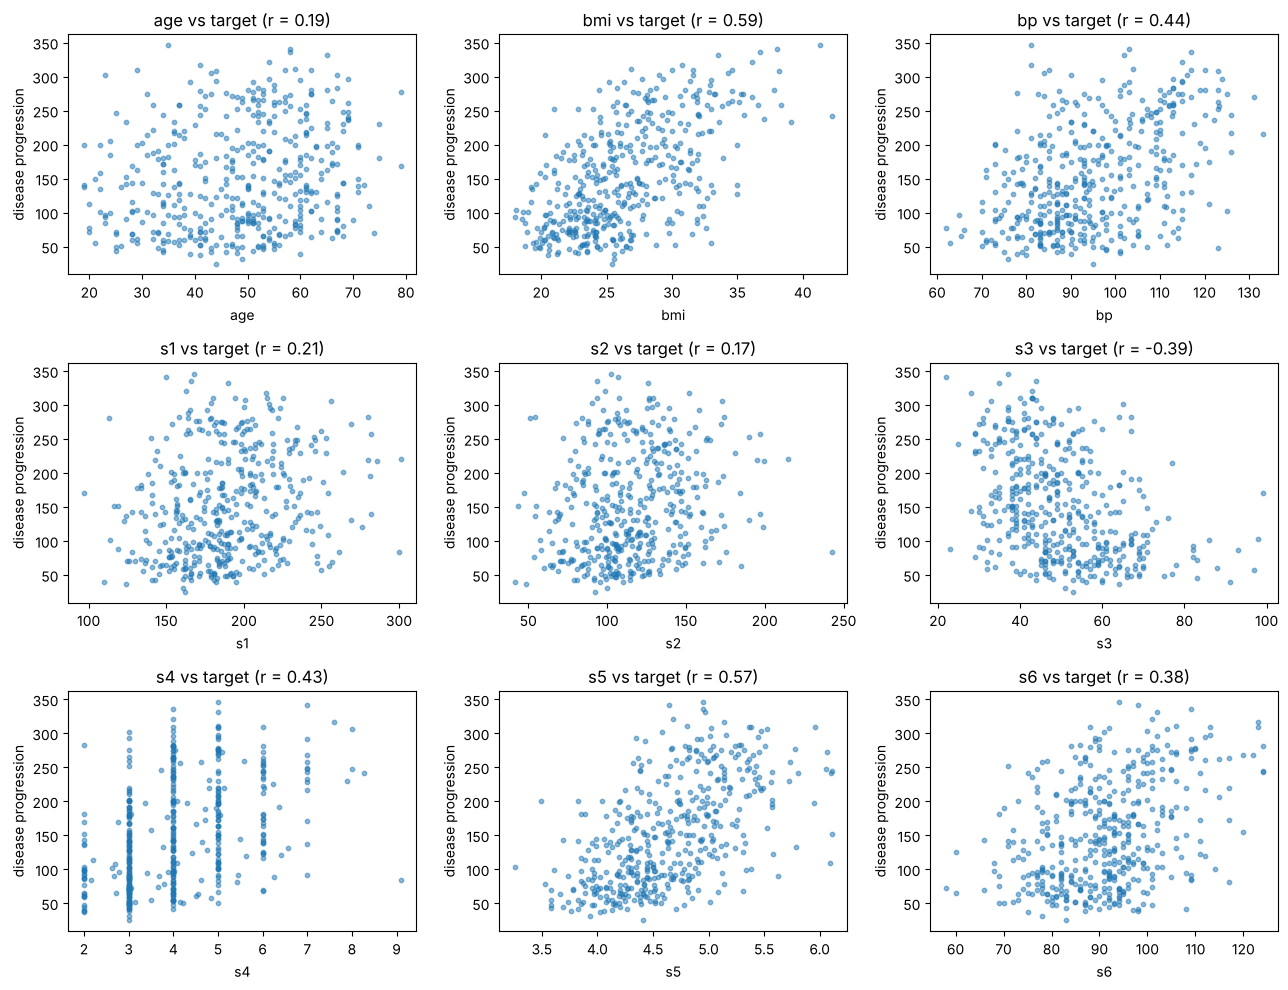

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.scatter(df[f], df[TARGET], s=10, alpha=0.5)
    r = df[f].corr(df[TARGET])
    ax.set_title(f"{f} vs target (r = {r:.2f})")
    ax.set_xlabel(f); ax.set_ylabel("disease progression")
plt.tight_layout(); plt.show()

Correlation of each feature with the target:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
s3    -0.395


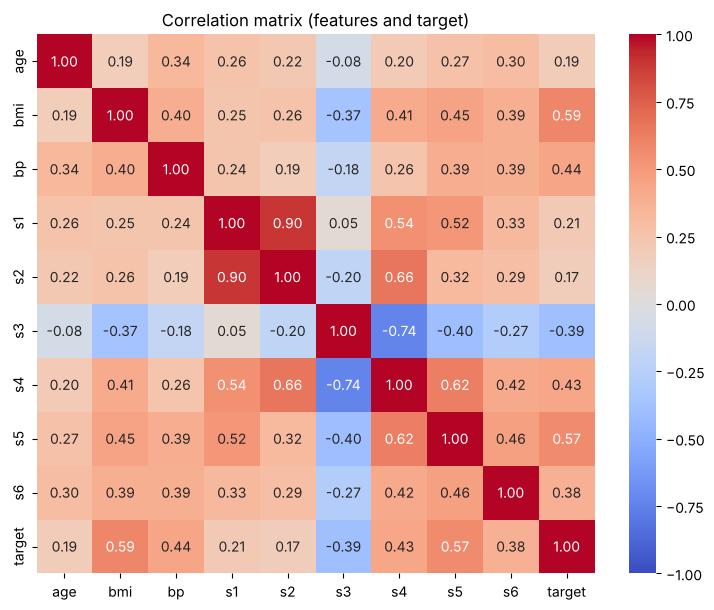

In [5]:
corr = df[FEATURES + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (features and target)")
plt.show()
print("Correlation of each feature with the target:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

In [6]:
# Strongly correlated PAIRS of input features (|r| > 0.7), a warning sign for multicollinearity
fc = df[FEATURES].corr()
pairs = [(a, b, round(fc.loc[a, b], 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if abs(fc.loc[a, b]) > 0.7]
pairs

[('s1', 's2', np.float64(0.9)), ('s3', 's4', np.float64(-0.74))]

**Observations:**
- `bmi` (r ≈ 0.59) and `s5` (≈ 0.57) show the strongest positive linear relationships with the target; `bp`, `s4` and `s6` are moderate; `s3` is negative (≈ −0.39), as expected for HDL; `age`, `s1`, `s2` are weak on their own.
- Among the inputs, **s1 and s2 are very strongly correlated (≈ 0.90)** and **s3 and s4 are strongly negatively correlated (≈ −0.74)**. These pairs carry overlapping information, so their individual coefficients may be unstable.
- The scatter plots look roughly linear with a lot of spread, so I expect a linear model to explain only part of the variation.
- **A high correlation does not prove causation.** A feature can correlate with progression because of a hidden third factor.

## 4. Manual calculation worksheet – normal equations by hand (Step 4)
I take a small sample of 7 patients and two features, **X1 = bmi** and **X2 = bp**, and solve **(XᵀX) b = Xᵀy** myself.

In [7]:
sample = df.sample(n=7, random_state=SEED)[["bmi", "bp", TARGET]].reset_index(drop=True)
sample.index = sample.index + 1
sample.index.name = "obs"
sample

,bmi,bp,target
obs,,,
1,25.8,90.00,219.0
2,29.8,101.00,70.0
3,26.0,91.00,202.0
4,31.2,117.67,230.0
5,24.5,94.00,111.0
6,24.1,87.00,84.0
7,42.2,99.00,242.0


In [8]:
np.set_printoptions(precision=4, suppress=True, linewidth=120)
x1 = sample["bmi"].to_numpy(); x2 = sample["bp"].to_numpy(); y_s = sample[TARGET].to_numpy()
n = len(sample)
X = np.column_stack([np.ones(n), x1, x2])        # design matrix: column of ones, X1, X2
print("Design matrix X (ones, bmi, bp):\n", X)
print("\ny vector:", y_s)

XtX = X.T @ X
Xty = X.T @ y_s
print("\nX^T X =\n", XtX)
print("\nX^T y =", Xty)

# Show how the entries of X^T X arise (sums), so every intermediate value is visible
print("\nSums used: n =", n, "| sum(x1) =", x1.sum(), "| sum(x2) =", x2.sum(),
      "| sum(x1^2) =", (x1**2).sum(), "| sum(x2^2) =", (x2**2).sum(), "| sum(x1*x2) =", (x1*x2).sum())
print("sum(y) =", y_s.sum(), "| sum(x1*y) =", (x1*y_s).sum(), "| sum(x2*y) =", (x2*y_s).sum())

Design matrix X (ones, bmi, bp):
 [[  1.    25.8   90.  ]
 [  1.    29.8  101.  ]
 [  1.    26.    91.  ]
 [  1.    31.2  117.67]
 [  1.    24.5   94.  ]
 [  1.    24.1   87.  ]
 [  1.    42.2   99.  ]]

y vector: [219.  70. 202. 230. 111.  84. 242.]

X^T X =
 [[    7.       203.6      679.67  ]
 [  203.6     6165.02   19946.604 ]
 [  679.67   19946.604  66634.2289]]

X^T y = [  1158.   35120.5 113926.1]

Sums used: n = 7 | sum(x1) = 203.60000000000002 | sum(x2) = 679.6700000000001 | sum(x1^2) = 6165.02 | sum(x2^2) = 66634.2289 | sum(x1*x2) = 19946.604
sum(y) = 1158.0 | sum(x1*y) = 35120.5 | sum(x2*y) = 113926.1


In [9]:
det = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
print("det(X^T X) =", round(det, 2), "(non-zero, so the inverse exists)")
print("(X^T X)^-1 =\n", XtX_inv)

b = XtX_inv @ Xty
b0, b1, b2 = b
print(f"\nSolved coefficients:  b0 = {b0:.4f},  b1 (bmi) = {b1:.4f},  b2 (bp) = {b2:.4f}")
print(f"Fitted equation (sample): y_hat = {b0:.3f} + {b1:.3f}*bmi + {b2:.3f}*bp")

# Check by elimination: the solver should agree with the inverse method
print("np.linalg.solve check:", np.linalg.solve(XtX, Xty))

det(X^T X) = 869831.75 (non-zero, so the inverse exists)
(X^T X)^-1 =
 [[14.8699 -0.0111 -0.1484]
 [-0.0111  0.0052 -0.0014]
 [-0.1484 -0.0014  0.002 ]]

Solved coefficients:  b0 = -71.4410,  b1 (bmi) = 5.2941,  b2 (bp) = 0.8537
Fitted equation (sample): y_hat = -71.441 + 5.294*bmi + 0.854*bp
np.linalg.solve check: [-71.441    5.2941   0.8537]


In [10]:
# Predict one observation and compute its residual (actual - predicted)
k = 3  # observation number (1-based)
xk = sample.loc[k, ["bmi", "bp"]].to_numpy()
yhat_k = b0 + b1*xk[0] + b2*xk[1]
print(f"Observation {k}: bmi = {xk[0]}, bp = {xk[1]}")
print(f"y_hat = {b0:.3f} + {b1:.3f}*{xk[0]} + {b2:.3f}*{xk[1]} = {yhat_k:.3f}")
print(f"actual y = {sample.loc[k, TARGET]},  residual = {sample.loc[k, TARGET] - yhat_k:.3f}")
print("\nAll residuals in the sample:", np.round(y_s - X @ b, 3), "| sum of residuals =", round((y_s - X @ b).sum(), 6))

Observation 3: bmi = 26.0, bp = 91.0
y_hat = -71.441 + 5.294*26.0 + 0.854*91.0 = 143.889
actual y = 202.0,  residual = 58.111

All residuals in the sample: [  77.024 -102.543   58.111   35.815  -27.509  -46.415    5.517] | sum of residuals = 0.0


**Check:** with an intercept in the model, least-squares residuals sum to (almost exactly) zero, and that is what we see. With only 7 points and 3 parameters the fit is fragile (4 degrees of freedom), so these hand-calculated coefficients are for *understanding the mechanics only*. They should not be trusted as estimates for the population.

## 5. Library models (Step 5): split, baselines, single vs multiple

In [11]:
# Verify the hand calculation with a library on the SAME 7 rows and 2 features
lib = LinearRegression().fit(sample[["bmi", "bp"]], sample[TARGET])
print("Library  :", round(lib.intercept_, 4), np.round(lib.coef_, 4))
print("By hand  :", round(b0, 4), np.round([b1, b2], 4))
print("Max absolute difference:", np.abs(np.r_[lib.intercept_, lib.coef_] - b).max())

Library  : -71.441 [5.2941 0.8537]
By hand  : -71.441 [5.2941 0.8537]
Max absolute difference: 7.290168468898628e-12


The two agree to numerical precision. Any difference is floating-point rounding only, because `LinearRegression` solves the same least-squares problem.

In [12]:
X_all, y_all = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of data in train/test:", round(len(X_train)/len(df), 2), "/", round(len(X_test)/len(df), 2))

Train: (353, 9) | Test: (89, 9)
Share of data in train/test: 0.8 / 0.2


In [13]:
def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate(model, Xte, yte, p):
    pred = model.predict(Xte)
    mse = mean_squared_error(yte, pred)
    r2 = r2_score(yte, pred)
    return {"MAE": mean_absolute_error(yte, pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2, "Adj R2": adj_r2(r2, len(yte), p)}

# Baseline 0: predict the training mean
base = DummyRegressor(strategy="mean").fit(X_train, y_train)
res_base = evaluate(base, X_test, y_test, p=0)

# Baseline 1: single feature = the one most correlated with the target (chosen using TRAIN data only)
best_feat = X_train.corrwith(y_train).abs().idxmax()
single = LinearRegression().fit(X_train[[best_feat]], y_train)
res_single = evaluate(single, X_test[[best_feat]], y_test, p=1)
print(f"Most correlated feature (train): {best_feat}")
print(f"Single-feature model: intercept = {single.intercept_:.3f}, coef({best_feat}) = {single.coef_[0]:.3f}, test R2 = {res_single['R2']:.3f}")

Most correlated feature (train): bmi
Single-feature model: intercept = -131.874, coef(bmi) = 10.763, test R2 = 0.233


In [14]:
# Multiple linear regression on all 9 features (train only)
multi = LinearRegression().fit(X_train, y_train)
res_multi = evaluate(multi, X_test, y_test, p=len(FEATURES))
coef_table = pd.DataFrame({"feature": FEATURES, "coefficient": multi.coef_}).set_index("feature")
print("Intercept:", round(multi.intercept_, 3))
coef_table

Intercept: -378.537


,coefficient
feature,
age,0.0127
bmi,6.3617
bp,1.0474
s1,-1.2171
s2,0.7990
s3,0.7168
s4,6.7676
s5,69.5340
s6,0.1577


In [15]:
# Standardised coefficients (scaler fitted on TRAIN only) to compare relative influence
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
multi_s = LinearRegression().fit(Xtr_s, y_train)
std_coef = pd.DataFrame({"raw coef": multi.coef_, "standardised coef": multi_s.coef_}, index=FEATURES)
print("Same predictions after scaling? ", np.allclose(multi.predict(X_test), multi_s.predict(Xte_s)))
std_coef.reindex(std_coef["standardised coef"].abs().sort_values(ascending=False).index)

Same predictions after scaling?  True


,raw coef,standardised coef
s1,-1.2171,-42.2103
s5,69.5340,36.4318
bmi,6.3617,27.8642
s2,0.7990,24.2725
bp,1.0474,14.7242
s3,0.7168,9.1463
s4,6.7676,8.7521
s6,0.1577,1.8389
age,0.0127,0.1617


## 6. Fitted equation and interpretation (Step 6)

In [16]:
terms = " ".join(f"{c:+.3f}*{f}" for f, c in zip(FEATURES, multi.coef_))
print(f"progression_hat = {multi.intercept_:.3f} {terms}")

progression_hat = -378.537 +0.013*age +6.362*bmi +1.047*bp -1.217*s1 +0.799*s2 +0.717*s3 +6.768*s4 +69.534*s5 +0.158*s6


**How to read the coefficients** (each is the change in the progression score for a one-unit increase, *holding the other features constant*):
- **bmi ≈ +6.4** per BMI unit, **bp ≈ +1.0** per mmHg, **s5 ≈ +69.5** per unit of log-triglycerides (one unit is large; s5 has std ≈ 0.52 and range ≈ 3.3–6.1).
- **Intercept ≈ −378.5:** the predicted score when *every* feature is 0. That is impossible here (nobody has age 0 or BMI 0), so the intercept is only a mathematical anchor, not something to interpret.
- **Warning signs of multicollinearity:** `s1` (−1.2) and `s2` (+0.8) have *opposite* signs although each is positively correlated with the target alone, and `s3` has a *positive* coefficient although its raw correlation is negative (≈ −0.39). Overlapping features are "sharing" the effect, so these individual signs should not be read literally.
- **Standardised coefficients** put all features on the same scale. By size, `s1`, `s5`, `bmi` and `s2` come first. But the large `s1`/`s2` values are inflated by their overlap (see VIF below), so I trust `bmi`, `s5` and `bp` more as relative-influence indicators. `age` is ≈ 0 once the others are included. This still does **not** prove causation.
- **Effect of scaling:** after standardising, a coefficient is the change in y per +1 standard deviation of that feature, so sizes become comparable. Raw coefficients depend on each feature's units. Predictions are unchanged by scaling (verified above).

## 7. Predictions on unseen data (Step 7)

In [17]:
pred_test = multi.predict(X_test)
cmp = pd.DataFrame({"actual": y_test.values, "predicted": pred_test.round(1)}, index=y_test.index)
cmp["error (actual - predicted)"] = (cmp["actual"] - cmp["predicted"]).round(1)
cmp.head(10)

,actual,predicted,error (actual - predicted)
287,219.0,130.9,88.1
211,70.0,168.6,-98.6
72,202.0,153.4,48.6
321,230.0,265.3,-35.3
73,111.0,132.8,-21.8
418,84.0,86.8,-2.8
367,242.0,276.2,-34.2
354,272.0,198.4,73.6
281,94.0,103.6,-9.6
148,96.0,126.0,-30.0


These are **test-set** predictions (the model never saw these rows while fitting).

**Differences:** most predictions are within about ±50 of the actual value, but some are far off, e.g. row 211 (actual 70, predicted 168.6, error −98.6) and row 287 (actual 219, predicted 130.9, error +88.1). The model tends to over-predict low actual values and under-predict high ones.

## 8. Evaluation (Step 8)

In [18]:
results = pd.DataFrame({"Mean baseline": res_base, f"Single ({best_feat})": res_single, "Multiple (9 features)": res_multi}).T
results

,MAE,MSE,RMSE,R2,Adj R2
Mean baseline,64.0065,5361.5335,73.2225,-0.0120,-0.0120
Single (bmi),52.2600,4061.8259,63.7325,0.2334,0.2245
Multiple (9 features),44.2677,2986.7329,54.6510,0.4363,0.3720


**Metric definitions:** MAE is the average absolute error; MSE is the average squared error (penalises large errors more); RMSE is the square root of MSE, in the units of the target; R² compares the model with the mean-based baseline (1 = perfect, 0 = same as the mean, can be negative on test data); adjusted R² penalises features that add little.

**What the numbers say:**
- **Mean baseline:** RMSE ≈ 73 and R² ≈ −0.01. Predicting the average gives a typical error of about one standard deviation of the target, and R² is slightly negative because the training mean is not exactly the test mean. This is the bar to beat.
- **Single feature (bmi):** RMSE ≈ 63.7, R² ≈ 0.23. BMI alone already explains about a quarter of the variation.
- **Multiple (9 features):** RMSE ≈ 54.7, MAE ≈ 44.3, R² ≈ 0.44, adjusted R² ≈ 0.37. The typical error is about 9 points lower than the single-feature model and R² roughly doubled. Adjusted R² is below R² because it charges a penalty for each of the 9 features (n = 89 test rows).
- **Is the extra complexity worth it?** Yes in accuracy terms, since the gain is large and it is measured on unseen data. But in context, an MAE of ≈ 44 on a target averaging ≈ 152 (about 29 %) and **over half of the variation still unexplained** means this model is a rough guide, not a precise forecaster.

## 9. Residual analysis, multicollinearity and assumptions (Step 9)

Residual mean: 3.68 | residual std: 54.53 | skew: -0.09


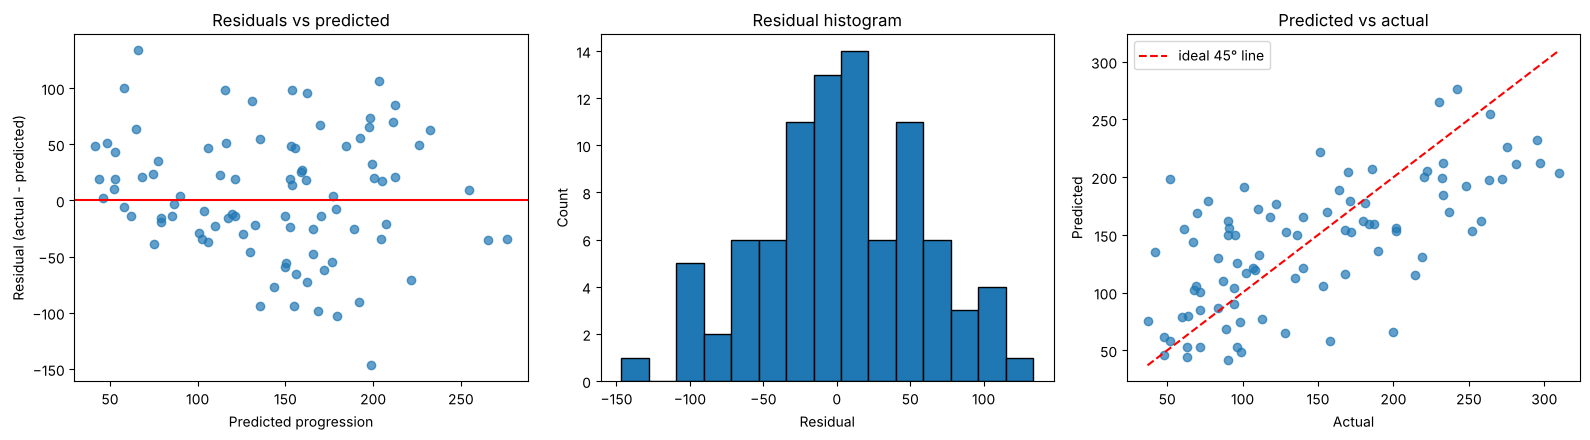

In [19]:
resid = y_test.values - pred_test
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(pred_test, resid, alpha=0.7); ax[0].axhline(0, color="red")
ax[0].set_xlabel("Predicted progression"); ax[0].set_ylabel("Residual (actual - predicted)"); ax[0].set_title("Residuals vs predicted")
ax[1].hist(resid, bins=15, edgecolor="k"); ax[1].set_xlabel("Residual"); ax[1].set_ylabel("Count"); ax[1].set_title("Residual histogram")
lo, hi = min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())
ax[2].scatter(y_test, pred_test, alpha=0.7); ax[2].plot([lo, hi], [lo, hi], "r--", label="ideal 45° line")
ax[2].set_xlabel("Actual"); ax[2].set_ylabel("Predicted"); ax[2].set_title("Predicted vs actual"); ax[2].legend()
plt.tight_layout(); plt.show()
print("Residual mean:", round(resid.mean(), 2), "| residual std:", round(resid.std(), 2), "| skew:", round(pd.Series(resid).skew(), 2))

In [20]:
# Variance Inflation Factor: VIF_j = 1 / (1 - R2_j), where R2_j comes from regressing feature j on the other features
def vif_table(frame):
    out = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        out[col] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

vif_all = vif_table(X_train)
vif_all.round(2)

s1     55.20
s2     35.76
s3     14.26
s5     10.06
s4      9.15
bmi     1.52
s6      1.50
bp      1.38
age     1.19
Name: VIF, dtype: float64

**Residual plots**
- *Residuals vs predicted:* the points are scattered around zero with no strong curve, and the spread looks roughly similar across the range (no obvious funnel), so linearity and constant variance look *reasonably* OK, though a few large residuals (≈ ±100–145) exist.
- *Histogram:* roughly symmetric and bell-like (mean ≈ 3.7, skew ≈ −0.1), so approximately normal errors look reasonable.
- *Predicted vs actual:* the points follow the 45° line only loosely. High actual values (> 250) are mostly **under-predicted** and low values are over-predicted, a typical "pull toward the average" for a model with modest R².

**Multicollinearity (VIF):** `s1` ≈ 55 and `s2` ≈ 36 are far above the usual warning level (≈ 5–10), `s3` ≈ 14, `s5` ≈ 10 and `s4` ≈ 9 are also high, while `bmi`, `bp`, `s6` and `age` are all below 2. This matches the correlation matrix (s1–s2 r ≈ 0.90; s3–s4 r ≈ −0.74). The lipid features are largely redundant.

**Assumptions check**
| Assumption | Verdict |
|---|---|
| Linearity | roughly reasonable (no clear curve in the residuals) |
| Independence of errors | assumed (each row is a different patient; no time order), cannot be fully verified |
| Constant variance | looks reasonable, not tested formally |
| Approximately normal errors | looks reasonable (histogram) |
| No severe multicollinearity | **violated** for s1/s2 (and partly s3/s4/s5) |

In [21]:
# Iterate once (stage 7): drop the most redundant lipid features and compare on the SAME test set
reduced = [f for f in FEATURES if f not in ("s1", "s2")]
multi_r = LinearRegression().fit(X_train[reduced], y_train)
res_red = evaluate(multi_r, X_test[reduced], y_test, p=len(reduced))
print("Features kept:", reduced)
print("VIF after dropping s1 and s2:"); print(vif_table(X_train[reduced]).round(2).to_string())
pd.DataFrame({"All 9": res_multi, f"Reduced ({len(reduced)})": res_red}).T

Features kept: ['age', 'bmi', 'bp', 's3', 's4', 's5', 's6']
VIF after dropping s1 and s2:
s4     3.19
s3     2.29
s5     1.99
bmi    1.50
s6     1.49
bp     1.37
age    1.18


,MAE,MSE,RMSE,R2,Adj R2
All 9,44.2677,2986.7329,54.6510,0.4363,0.3720
Reduced (7),43.8783,2927.0620,54.1023,0.4475,0.3998


**One improvement tried:** dropping `s1` and `s2` (the most redundant pair) leaves every remaining VIF below about 3.2, while test performance did **not** get worse: RMSE ≈ 54.1 vs 54.7, R² ≈ 0.45 vs 0.44, and adjusted R² improves from ≈ 0.37 to ≈ 0.40. The simpler model predicts equally well and its coefficients are more trustworthy, so it is the better choice to report to a manager. (The gain is small and the test set has only 89 rows, so I would confirm with cross-validation before claiming it is truly better.)

## 10. New prediction and conclusion (Step 10)

In [22]:
print(df[FEATURES].describe().loc[["min", "max"]].round(1).to_string())
new = pd.DataFrame([{"age": 50, "bmi": 27.0, "bp": 95.0, "s1": 190.0, "s2": 115.0, "s3": 50.0, "s4": 4.0, "s5": 4.65, "s6": 91.0}])
inside = ((new.iloc[0] >= df[FEATURES].min()) & (new.iloc[0] <= df[FEATURES].max())).all()
print("\nAll new values inside the training range?", inside)
print(f"Predicted disease-progression score: {multi.predict(new)[0]:.1f}  (units: the dataset's progression score; typical range 25-346)")

      age   bmi     bp     s1     s2    s3   s4   s5     s6
min  19.0  18.0   62.0   97.0   41.6  22.0  2.0  3.3   58.0
max  79.0  42.2  133.0  301.0  242.4  99.0  9.1  6.1  124.0

All new values inside the training range? True
Predicted disease-progression score: 154.6  (units: the dataset's progression score; typical range 25-346)


**New example:** a 50-year-old with BMI 27, blood pressure 95 and typical lipid/glucose values (all inside the range seen in training, so this is interpolation, not extrapolation) gets a predicted progression score of about **155**, close to the dataset average (≈ 152), which makes sense for a fairly average patient profile.

**Conclusion.** Using 442 patients and nine baseline measurements, a multiple linear regression explains about 44 % of the variation in disease progression on unseen data (RMSE ≈ 55), clearly beating both the mean baseline (RMSE ≈ 73) and the BMI-only model (RMSE ≈ 64). BMI, blood pressure and the triglyceride marker (`s5`) are the most reliable contributors; the cholesterol measures overlap heavily, and a reduced model without `s1` and `s2` performs as well. Features can overlap in the information they carry, more features do not automatically help, and a linear model can miss non-linear effects and factors that are not in the data.

## Decision log
| # | Decision | Alternatives considered | Reason |
|---|---|---|---|
| 1 | Used the raw-unit version of the diabetes data | pre-standardised version | coefficients can be explained in real units |
| 2 | Dropped `sex` | keep it | protected attribute, binary-coded; no clinical argument for using it in this exploratory model |
| 3 | No rows removed, no imputation | remove outliers | no missing/duplicate values; extreme values look plausible for patients, not errors |
| 4 | Best single feature chosen on **training** data only | choose on full data | avoids leaking test information |
| 5 | 80:20 split, `random_state=42` | k-fold CV | assignment asks for a split; CV would be the next step for a more stable estimate |
| 6 | Kept all 9 features for the main model, then tested a reduced model | drop by correlation alone | let the test metrics (adjusted R², RMSE) and VIF decide, see section 9 |
| 7 | Scaling used **only** to compare coefficients | scale everything | OLS predictions are unchanged by scaling (verified above) |

## Limitations and ethics
- Only 442 patients from one study; I cannot say if results hold for other populations.
- A linear model ignores non-linear effects and interactions, and the data lacks many real drivers (diet, medication, genetics).
- Coefficients describe association, **not causation**. Multicollinearity makes individual lipid coefficients unreliable.
- **Should not be used** to make treatment decisions for an individual patient. A prediction is an estimate, not a guarantee. Wrong predictions could lead to under- or over-treatment of patients.
- Predictions are only valid inside the range of the training data (checked for the new example).